# 02 · Train the eye-signal classifier
Load recordings → quick data check → 1 s windows (step 100 ms) → features → LightGBM →
**leave-one-person-out** evaluation → false activations (rules vs classifier) → export
`web/public/models/signal.onnx` + `signal_meta.json`.

Run top to bottom. Recordings stay local in `ml/recordings/` (not in git).

In [1]:
import json, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
REC = ROOT / "ml" / "recordings"
OUT_MODEL = ROOT / "web" / "public" / "models"; OUT_MODEL.mkdir(parents=True, exist_ok=True)
OUT_RES = ROOT / "ml" / "results"; OUT_RES.mkdir(parents=True, exist_ok=True)

CLASSES = ["idle", "natural_blink", "long_blink", "left", "right", "brow_up"]
WIN_S, STEP_S = 1.0, 0.1          # window length / inference step
CLOSED_DELTA = 0.30               # eyes "closed" when blink > rest + 0.30
LONG_MIN_S = 0.30                 # closed this long → counts as long_blink (earlier = ambiguous)
NAT_AFTER_S = 0.30                # window ending ≤ 0.3 s after a short closure → natural_blink
print("recordings:", REC)

recordings: /Users/yashvarpe/Desktop/UBHack/blink-talk/ml/recordings


## Load all recordings

In [2]:
def base_person(p):
    return re.sub(r"[_-]?glasses$", "", p)

sessions = []
for f in sorted(REC.glob("*.json")):
    d = json.load(open(f))
    names = d["bsNames"]
    fr = [x for x in d["frames"] if x.get("faceFound")]
    if len(fr) < 100:
        print("skip (too few frames):", f.name); continue
    bs = np.array([x["bs"] for x in fr], dtype=float)
    col = lambda n: bs[:, names.index(n)]
    df = pd.DataFrame({
        "t": np.array([x["t"] for x in fr]) / 1000.0,
        "label": [x["label"] for x in fr],
        "trial": [x["trial"] for x in fr],
        "blink": [x["blink"] for x in fr],
        "h": [x["lookA"] - x["lookB"] for x in fr],
        "lookA": [x["lookA"] for x in fr],
        "lookB": [x["lookB"] for x in fr],
        "brow": [x["brow"] for x in fr],
        "yaw": [x["yaw"] for x in fr],
        "pitch": [x["pitch"] for x in fr],
        "jaw": col("jawOpen"),
        "smile": (col("mouthSmileLeft") + col("mouthSmileRight")) / 2,
    })
    m = re.match(r"(.+?)_(guided|normal)_", f.name)       # person from file name (more reliable)
    person = m.group(1) if m else d["person"]
    sessions.append({"file": f.name, "person": person, "group": base_person(person),
                     "session": d["session"], "df": df})

summary = pd.DataFrame([{"file": s["file"], "group": s["group"], "session": s["session"],
                         "frames": len(s["df"]), "secs": round(s["df"].t.iloc[-1], 1),
                         "fps": round(len(s["df"]) / s["df"].t.iloc[-1], 1)} for s in sessions])
summary

,file,group,session,frames,secs,fps
0,atharvatupe_guided_2026-11-08-02-10-53.json,atharvatupe,guided,8476,175.6,48.3
1,atharvatupe_normal_2026-11-08-02-13-15.json,atharvatupe,normal,7508,125.1,60.0
2,omwaikar_guided_2026-11-08-02-17-00.json,omwaikar,guided,10601,176.7,60.0
3,omwaikar_normal_2026-11-08-02-19-33.json,omwaikar,normal,6984,125.0,55.9
4,udayanjadhav_glasses_guided_2026-11-08-02-43-1...,udayanjadhav,guided,10593,176.5,60.0
5,udayanjadhav_guided_2026-11-08-02-26-00.json,udayanjadhav,guided,10492,174.9,60.0
6,udayanjadhav_normal_2026-11-08-02-29-45.json,udayanjadhav,normal,7486,124.7,60.0
7,yashvarpe_glasses_guided_2026-11-08-02-39-35.json,yashvarpe,guided,10747,179.1,60.0
8,yashvarpe_guided_2026-11-08-01-57-51.json,yashvarpe,guided,5333,177.7,30.0
9,yashvarpe_normal_2026-11-08-02-00-35.json,yashvarpe,normal,3753,125.1,30.0


## Rest (calibration) values per session
In the app, `calibrate.ts` measures these during the "rest 3 s" step. Here: median of the guided "look at the dot and relax" holds.
Normal sessions borrow the rest values of the same person's guided session.

In [3]:
REST_KEYS = ["blink", "h", "lookA", "lookB", "brow", "yaw", "pitch"]
def rest_of(df):
    holds = df[(df.label == "idle") & (df.trial >= 0)]
    if len(holds) < 30:
        holds = df
    return {k: float(holds[k].median()) for k in REST_KEYS}

def h_sign(df):
    """+1 if looking LEFT raises h in this session, -1 if it lowers it (from the guided left/right trials)"""
    L = df[df.label == "left"].h.median(); R = df[df.label == "right"].h.median()
    return 1.0 if (np.isnan(L) or np.isnan(R) or L >= R) else -1.0

rest_by_person, sign_by_person = {}, {}
for s in sessions:
    if s["session"] == "guided":
        s["rest"] = rest_of(s["df"]); s["hsign"] = h_sign(s["df"])
        for key in (s["person"], s["group"]):
            rest_by_person.setdefault(key, s["rest"]); sign_by_person.setdefault(key, s["hsign"])
for s in sessions:
    if "rest" not in s:
        s["rest"] = rest_by_person.get(s["person"]) or rest_by_person.get(s["group"]) or rest_of(s["df"])
        s["hsign"] = sign_by_person.get(s["person"], sign_by_person.get(s["group"], 1.0))

pd.DataFrame({s["file"]: {**s["rest"], "hsign": s["hsign"]} for s in sessions}).T.round(3)

,blink,h,lookA,lookB,brow,yaw,pitch,hsign
atharvatupe_guided_2026-11-08-02-10-53.json,0.146,-0.072,0.037,0.109,0.000,0.907,4.584,1.0
atharvatupe_normal_2026-11-08-02-13-15.json,0.146,-0.072,0.037,0.109,0.000,0.907,4.584,1.0
omwaikar_guided_2026-11-08-02-17-00.json,0.035,-0.037,0.048,0.085,0.011,4.416,1.463,1.0
omwaikar_normal_2026-11-08-02-19-33.json,0.035,-0.037,0.048,0.085,0.011,4.416,1.463,1.0
udayanjadhav_glasses_guided_2026-11-08-02-43-11.json,0.197,-0.003,0.071,0.078,0.002,2.338,3.050,1.0
udayanjadhav_guided_2026-11-08-02-26-00.json,0.258,0.071,0.132,0.063,0.001,1.436,2.553,1.0
udayanjadhav_normal_2026-11-08-02-29-45.json,0.197,-0.003,0.071,0.078,0.002,2.338,3.050,1.0
yashvarpe_glasses_guided_2026-11-08-02-39-35.json,0.161,0.196,0.213,0.016,0.005,-2.616,-0.286,1.0
yashvarpe_guided_2026-11-08-01-57-51.json,0.114,0.138,0.162,0.024,0.012,-1.992,-5.585,1.0
yashvarpe_normal_2026-11-08-02-00-35.json,0.161,0.196,0.213,0.016,0.005,-2.616,-0.286,1.0


## Quick data check: each label should look different

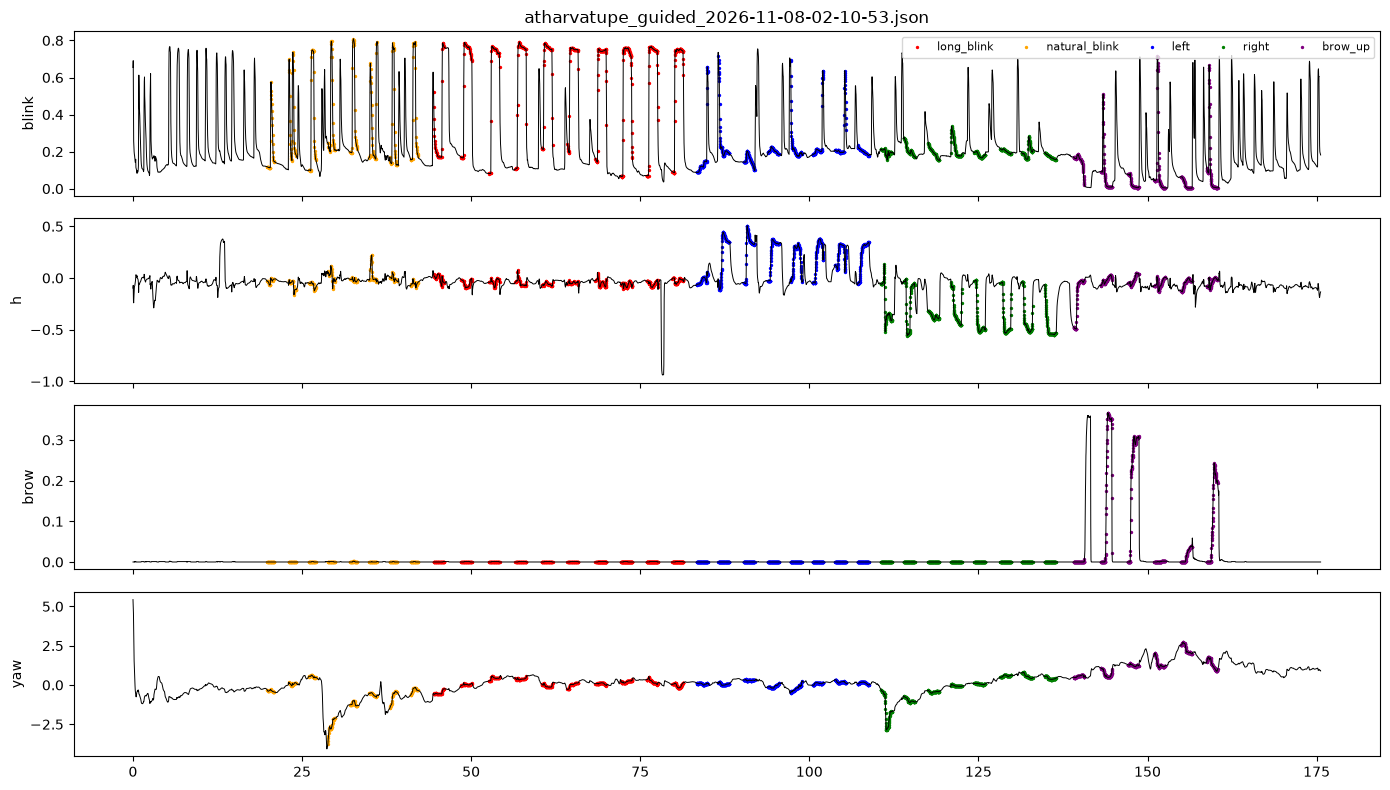

In [4]:
g = sessions[0]
d = g["df"]
fig, ax = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for a, k in zip(ax, ["blink", "h", "brow", "yaw"]):
    a.plot(d.t, d[k], lw=0.7, color="k")
    for lab, c in [("long_blink", "red"), ("natural_blink", "orange"), ("left", "blue"), ("right", "green"), ("brow_up", "purple")]:
        m = d.label == lab
        a.scatter(d.t[m], d[k][m], s=2, color=c, label=lab)
    a.set_ylabel(k)
ax[0].legend(ncol=5, fontsize=8); ax[0].set_title(g["file"]); plt.tight_layout(); plt.show()

## Frame labels → refined labels
The recorder labels the whole cue window. People react late, so we refine using the signal itself:
- `long_blink`: eyes closed ≥ 0.3 s inside a long-blink trial (shorter closed = ambiguous → dropped)
- `natural_blink`: the 0.3 s right after any short closure (< 0.4 s) reopens, in any session
- `left` / `right` / `brow_up`: frames past half of that trial's peak; the rest of the trial is dropped
- guided rest periods with big gaze/brow movement (transitions) are dropped
- normal sessions: everything is `idle` (talking, laughing, looking around = hard negatives), except natural blinks

In [5]:
def closure_runs(t, closed):
    """list of (start_idx, end_idx_inclusive) of consecutive closed frames"""
    runs, i, n = [], 0, len(closed)
    while i < n:
        if closed[i]:
            j = i
            while j + 1 < n and closed[j + 1]: j += 1
            runs.append((i, j)); i = j + 1
        else:
            i += 1
    return runs

def refine(s):
    d = s["df"].copy(); r = s["rest"]
    rel = {k: d[k].values - r[k] for k in REST_KEYS}
    if s["hsign"] < 0:                       # make "left" always raise h
        rel["h"] = -rel["h"]
        rel["lookA"], rel["lookB"] = rel["lookB"], rel["lookA"]
    t = d.t.values
    closed = rel["blink"] > CLOSED_DELTA
    dt = np.median(np.diff(t))
    cd = np.zeros(len(d))                    # closed duration so far, per frame
    for a, b in closure_runs(t, closed):
        cd[a:b + 1] = t[a:b + 1] - t[a] + dt
    lab = np.array(d.label.values, dtype=object)
    out = np.array(["idle"] * len(d), dtype=object)
    if s["session"] == "guided":
        out[:] = lab
        for tr in d.trial.unique():
            if tr < 0: continue
            m = (d.trial.values == tr)
            L = lab[m][0]
            if L == "long_blink":
                out[m] = np.where(closed[m] & (cd[m] >= LONG_MIN_S), "long_blink", np.where(closed[m], "drop", "idle"))
            elif L == "left":
                pk = rel["h"][m].max()
                out[m] = np.where(rel["h"][m] > 0.5 * pk, "left", "drop") if pk > 0.2 else "drop"
            elif L == "right":
                pk = rel["h"][m].min()
                out[m] = np.where(rel["h"][m] < 0.5 * pk, "right", "drop") if pk < -0.2 else "drop"
            elif L == "brow_up":
                pk = rel["brow"][m].max(); out[m] = np.where(rel["brow"][m] > 0.5 * pk, "brow_up", "drop")
            elif L == "natural_blink":
                out[m] = "idle"              # handled below by the generic short-closure rule
        rest_m = (lab == "idle")             # transitions during rest periods
        moving = (np.abs(rel["h"]) > 0.30) | (rel["brow"] > 0.20)
        out[rest_m & moving] = "drop"
    for a, b in closure_runs(t, closed):     # closures
        length = t[b] - t[a] + dt
        seg = np.arange(a, b + 1)
        if s["session"] == "guided" and (lab[seg] == "long_blink").any():
            out[seg] = np.where(cd[seg] >= LONG_MIN_S, "long_blink", "drop")
            continue
        out[a:b + 1] = "drop"                # mid-closure: ambiguous
        if length < 0.4:
            after = (t > t[b]) & (t <= t[b] + NAT_AFTER_S)
            out[after & (out != "drop")] = "natural_blink"
        elif s["session"] == "normal":
            out[seg[cd[seg] >= LONG_MIN_S]] = "idle"   # long closure while talking = hard negative
    if s["session"] == "normal":             # glances while talking: don't teach "looking sideways = idle"
        out[(np.abs(rel["h"]) > 0.30) & (out == "idle")] = "drop"
    d["y"] = out
    d["closed"] = closed
    d["cd"] = cd
    for k in REST_KEYS:
        d[k + "_rel"] = rel[k]
    s["ref"] = d

for s in sessions:
    refine(s)
pd.concat([s["ref"].assign(group=s["group"]) for s in sessions]).groupby(["group", "y"]).size().unstack(fill_value=0)

y,brow_up,drop,idle,left,long_blink,natural_blink,right
group,,,,,,,
atharvatupe,245,4768,7754,463,413,1770,571
omwaikar,216,4537,9676,20,651,1902,583
udayanjadhav,317,5930,16835,1125,1085,2172,1107
yashvarpe,477,3367,12917,810,869,581,812


## Windows → features
Must match `web/lib/signals.ts` exactly (the list is saved to `signal_meta.json`).

In [6]:
SERIES = ["blink_rel", "h_rel", "lookA_rel", "lookB_rel", "brow_rel", "yaw_rel", "pitch_rel", "jaw", "smile"]
STATS = ["mean", "min", "max", "last", "slope"]
FEATURES = [f"{s}_{st}" for s in SERIES for st in STATS] + \
           ["closed_dur", "longest_closure", "n_closures", "frac_closed", "since_closure"]

def window_features(t, X, closed, cd, i0, i1):
    """features for frames i0..i1 (inclusive); t in seconds"""
    tw = t[i0:i1 + 1]; f = []
    x = tw - tw.mean(); den = float((x * x).sum()) or 1e-9
    for j in range(X.shape[1]):
        v = X[i0:i1 + 1, j]
        f += [v.mean(), v.min(), v.max(), v[-1], float((x * (v - v.mean())).sum() / den)]
    c = closed[i0:i1 + 1]
    dt = np.median(np.diff(tw)) if len(tw) > 1 else 1 / 30
    runs = closure_runs(tw, c)
    lengths = [tw[b] - tw[a] + dt for a, b in runs]
    since = 1.0
    if runs and not c[-1]:
        since = min(1.0, tw[-1] - tw[runs[-1][1]])
    elif c[-1]:
        since = 0.0
    f += [cd[i1], max(lengths) if lengths else 0.0, float(len(runs)), float(c.mean()), since]
    return f

def make_windows(s):
    d = s["ref"]; t = d.t.values
    X = d[SERIES].values.astype(float); closed = d.closed.values; cd = d.cd.values
    rows, ys, tes = [], [], []
    te = t[0] + WIN_S
    while te <= t[-1]:
        i1 = np.searchsorted(t, te, side="right") - 1
        i0 = np.searchsorted(t, te - WIN_S, side="left")
        if i1 - i0 >= 10 and d.y.values[i1] != "drop":
            rows.append(window_features(t, X, closed, cd, i0, i1)); ys.append(d.y.values[i1]); tes.append(te)
        te += STEP_S
    return np.array(rows, dtype=np.float32), np.array(ys), np.array(tes)

W = []
for s in sessions:
    Xs, ys, tes = make_windows(s)
    W.append(pd.DataFrame(Xs, columns=FEATURES).assign(y=ys, te=tes, group=s["group"], session=s["session"], file=s["file"]))
W = pd.concat(W, ignore_index=True)
print(W.shape)
W.groupby(["group", "y"]).size().unstack(fill_value=0)

(11945, 55)


y,brow_up,idle,left,long_blink,natural_blink,right
group,,,,,,
atharvatupe,40,1496,78,98,339,94
omwaikar,36,1622,3,108,308,96
udayanjadhav,53,2790,190,177,353,185
yashvarpe,112,3066,169,193,160,179


## Leave-one-person-out evaluation
Weights: every (person, class) pair counts equally → no person or class dominates.

In [7]:
def weights(df):
    cnt = df.groupby(["group", "y"]).y.transform("size")
    return (1.0 / cnt).values

PARAMS = dict(n_estimators=150, learning_rate=0.08, num_leaves=15, min_child_samples=10,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

groups = sorted(W.group.unique())
W["pred"] = None
for g in groups:
    tr, te = W[W.group != g], W[W.group == g]
    if tr.y.nunique() < len(CLASSES):
        print("warning: training set misses classes when holding out", g)
    m = lgb.LGBMClassifier(**PARAMS)
    m.fit(tr[FEATURES], tr.y, sample_weight=weights(tr))
    W.loc[te.index, "pred"] = m.predict(te[FEATURES])
    proba = m.predict_proba(te[FEATURES])
    for k, c in enumerate(m.classes_):
        W.loc[te.index, "p_" + c] = proba[:, k]

guided = W[W.session == "guided"]
correct = (guided.pred == guided.y)
per_class = correct.groupby(guided.y).mean().reindex(CLASSES)
per_person = correct.groupby(guided.group).mean()
print("Per-class recall (held-out person, guided windows):"); print(per_class.round(3))
print("\nPer-person accuracy:"); print(per_person.round(3))
pd.crosstab(guided.y, guided.pred, rownames=["true"], colnames=["pred"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

Per-class recall (held-out person, guided windows):
y
idle             0.995
natural_blink    0.986
long_blink       1.000
left             0.945
right            0.975
brow_up          0.880
dtype: float64

Per-person accuracy:
group
atharvatupe     0.966
omwaikar        0.985
udayanjadhav    0.992
yashvarpe       0.996
dtype: float64


pred,idle,natural_blink,long_blink,left,right,brow_up
true,,,,,,
idle,6508,9,0,3,13,7
natural_blink,5,563,0,0,0,3
long_blink,0,0,576,0,0,0
left,24,0,0,416,0,0
right,14,0,0,0,540,0
brow_up,27,0,0,2,0,212


In [8]:
print(pd.crosstab(guided.y, guided.pred).reindex(index=CLASSES, columns=CLASSES, fill_value=0), "\n")
for s in sessions:
    d = s["ref"]
    if s["session"] == "guided":
        print(f"{s['file'][:32]:32s} left h_rel={d[d.label=='left'].h_rel.median():+.2f}  "
              f"right h_rel={d[d.label=='right'].h_rel.median():+.2f}")
    else:
        q = d.h_rel.quantile([.02, .98]).round(2).tolist()
        print(f"{s['file'][:32]:32s} NORMAL h_rel 2%..98% = {q}  "
              f"time with h_rel>+0.3: {(d.h_rel > 0.3).mean():.1%}  <-0.3: {(d.h_rel < -0.3).mean():.1%}")

pred           idle  natural_blink  long_blink  left  right  brow_up
y                                                                   
idle           6508              9           0     3     13        7
natural_blink     5            563           0     0      0        3
long_blink        0              0         576     0      0        0
left             24              0           0   416      0        0
right            14              0           0     0    540        0
brow_up          27              0           0     2      0      212 

atharvatupe_guided_2026-11-08-02 left h_rel=+0.37  right h_rel=-0.33
atharvatupe_normal_2026-11-08-02 NORMAL h_rel 2%..98% = [-0.81, 0.59]  time with h_rel>+0.3: 10.9%  <-0.3: 23.9%
omwaikar_guided_2026-11-08-02-17 left h_rel=+0.01  right h_rel=-0.40
omwaikar_normal_2026-11-08-02-19 NORMAL h_rel 2%..98% = [-0.75, 0.86]  time with h_rel>+0.3: 22.3%  <-0.3: 13.2%
udayanjadhav_glasses_guided_2026 left h_rel=+0.73  right h_rel=-0.51
udayanjadhav_

## Events: rules vs classifier
Event decoding (same as `signals.ts`):
- **classifier**: `select` when p(long_blink) ≥ 0.5 for 2 inferences in a row; `move` when p(left|right) ≥ 0.5
  for 4 in a row (0.4 s dwell: ignores quick glances); `undo` when p(brow_up) ≥ 0.5 for 2 in a row.
  After an event, wait until p(idle) + p(natural_blink) ≥ 0.5 before the next one.
- **rules v1**: closed 0.6–5 s → select; |h_rel| > half of the person's guided peak for 0.3 s → move; brow_rel > half peak → undo.

Measured on held-out people only.

In [9]:
DEC = {"p_min": 0.5, "consec": {"select": 2, "move": 4, "undo": 2}, "rearm_p_idle": 0.5}

def decode_classifier(sw):
    """sw: windows of one session → list of (window_end_time, event)"""
    ev, state, run = [], None, {"select": 0, "move": 0, "undo": 0}
    for r in sw.sort_values("te").itertuples():
        cand = {"select": r.p_long_blink, "move": r.p_left + r.p_right, "undo": r.p_brow_up}
        for k, p in cand.items():
            run[k] = run[k] + 1 if p >= DEC["p_min"] else 0
        if state is None:
            for k in ["select", "move", "undo"]:
                if run[k] >= DEC["consec"][k]:
                    ev.append((r.te, k)); state = k; break
        elif r.p_idle + r.p_natural_blink >= DEC["rearm_p_idle"]:
            state = None
    return ev

def peaks(s):
    d = s["ref"]
    def pk(lab, col, fn):
        x = d[d.label == lab]
        return fn(x.groupby("trial")[col].agg("max" if fn is np.max else "min")) if len(x) else np.nan
    return {"left": pk("left", "h_rel", np.max), "right": pk("right", "h_rel", np.min),
            "brow": pk("brow_up", "brow_rel", np.max)}

def decode_rules(s, pk):
    d = s["ref"]; t = d.t.values; ev = []
    for a, b in closure_runs(t, d.closed.values):
        L = t[b] - t[a]
        if 0.6 <= L <= 5: ev.append((t[a], "select"))
    def runs_over(mask, min_s):
        n = 0
        for a, b in closure_runs(t, mask):
            if t[b] - t[a] >= min_s: n += 1
        return n
    moves = runs_over(d.h_rel.values > 0.5 * np.nanmedian(pk["left"]), 0.3) + \
            runs_over(d.h_rel.values < 0.5 * np.nanmedian(pk["right"]), 0.3)
    undos = runs_over(d.brow_rel.values > 0.5 * np.nanmedian(pk["brow"]), 0.2)
    sel = sum(1 for e in ev if e[1] == "select")
    return {"select": sel, "move": moves, "undo": undos}

rows = []
for s in sessions:
    if s["session"] != "normal": continue
    mins = s["ref"].t.iloc[-1] / 60
    gs = [x for x in sessions if x["group"] == s["group"] and x["session"] == "guided"]
    pk = peaks(gs[0]) if gs else {"left": np.nan, "right": np.nan, "brow": np.nan}
    rr = decode_rules(s, pk)
    sw = W[(W.file == s["file"])]
    ce = decode_classifier(sw)
    cc = {k: sum(1 for _, e in ce if e == k) for k in ["select", "move", "undo"]}
    rows.append({"person": s["group"], "minutes": round(mins, 2),
                 **{f"rules_{k}_per_min": round(v / mins, 2) for k, v in rr.items()},
                 **{f"clf_{k}_per_min": round(v / mins, 2) for k, v in cc.items()}})
false_act = pd.DataFrame(rows)
false_act

,person,minutes,rules_select_per_min,rules_move_per_min,rules_undo_per_min,clf_select_per_min,clf_move_per_min,clf_undo_per_min
0,atharvatupe,2.09,0.96,23.50,0.00,1.44,0.0,0.00
1,omwaikar,2.08,0.48,31.68,1.92,0.96,0.0,1.44
2,udayanjadhav,2.08,0.00,16.35,0.00,0.00,0.0,0.00
3,yashvarpe,2.09,0.48,12.95,0.48,0.48,0.0,0.00


## Detection: did each deliberate gesture (held-out person) trigger its event?
A trial counts as detected if the right event fires between the cue and 0.8 s after it ends.

In [10]:
want = {"long_blink": "select", "left": "move", "right": "move", "brow_up": "undo"}
det = []
for s in sessions:
    if s["session"] != "guided": continue
    ev = decode_classifier(W[W.file == s["file"]])
    d = s["ref"]
    trials = d[d.trial >= 0].groupby("trial").agg(label=("label", "first"), t0=("t", "min"), t1=("t", "max"))
    for _, r in trials.iterrows():
        if r.label in want:
            ok = any(e == want[r.label] and r.t0 <= te <= r.t1 + 0.8 for te, e in ev)
            det.append({"person": s["group"], "file": s["file"], "label": r.label, "detected": ok})
det = pd.DataFrame(det)

detection = det.groupby("label").detected.agg(["sum", "count"])
detection["rate"] = (detection["sum"] / detection["count"]).round(3)
print("Detection per gesture:"); print(detection)

print("\nDetection rate per person:")
print(det.groupby(["person", "label"]).detected.mean().unstack().round(2))

print("\nDetection rate per session (glasses vs not):")
print(det.groupby(["file", "label"]).detected.mean().unstack().round(2))
detection

Detection per gesture:
            sum  count   rate
label                        
brow_up      27     36  0.750
left         38     48  0.792
long_blink   57     60  0.950
right        48     48  1.000

Detection rate per person:
label         brow_up  left  long_blink  right
person                                        
atharvatupe      0.50  0.75         1.0    1.0
omwaikar         0.50  0.00         0.7    1.0
udayanjadhav     0.75  1.00         1.0    1.0
yashvarpe        1.00  1.00         1.0    1.0

Detection rate per session (glasses vs not):
label                                               brow_up  left  long_blink  \
file                                                                            
atharvatupe_guided_2026-11-08-02-10-53.json            0.50  0.75         1.0   
omwaikar_guided_2026-11-08-02-17-00.json               0.50  0.00         0.7   
udayanjadhav_glasses_guided_2026-11-08-02-43-11...     0.83  1.00         1.0   
udayanjadhav_guided_2026-11-08-02-26

,sum,count,rate
label,,,
brow_up,27,36,0.750
left,38,48,0.792
long_blink,57,60,0.950
right,48,48,1.000


## Train the final model on everyone and export ONNX

In [11]:
from onnxmltools import convert_lightgbm
from onnxmltools.convert.common.data_types import FloatTensorType
import onnxruntime as ort

final = lgb.LGBMClassifier(**PARAMS)
final.fit(W[FEATURES], W.y, sample_weight=weights(W))
onx = convert_lightgbm(final, initial_types=[("input", FloatTensorType([None, len(FEATURES)]))],
                       zipmap=False, target_opset=15)
path = OUT_MODEL / "signal.onnx"
path.write_bytes(onx.SerializeToString())

sess = ort.InferenceSession(str(path))
out_names = [o.name for o in sess.get_outputs()]
probs = sess.run(None, {"input": W[FEATURES].values[:200].astype(np.float32)})[1]
ref = final.predict_proba(W[FEATURES].values[:200])
print("onnx outputs:", out_names, "| max diff vs lightgbm:", float(np.abs(probs - ref).max()))
print("size:", round(path.stat().st_size / 1024), "KB")

meta = {
    "classes": [str(c) for c in final.classes_],
    "features": FEATURES,
    "series": SERIES, "stats": STATS,
    "input": "input", "outputs": out_names,
    "window_s": WIN_S, "step_s": STEP_S,
    "closed_delta": CLOSED_DELTA,
    "rest_keys": REST_KEYS,
    "decode": DEC,
    "definitions": {
        "h": "lookA - lookB", "jaw": "jawOpen", "smile": "(mouthSmileLeft + mouthSmileRight)/2",
        "*_rel": "value - rest value from calibration (rest step median)",
        "closed": "blink_rel > closed_delta",
        "slope": "least-squares slope per second over the window (time in seconds)",
        "closed_dur": "seconds the eyes have been closed continuously at the window end (0 if open)",
        "longest_closure": "longest closed run inside the window, seconds",
        "n_closures": "number of closed runs inside the window",
        "frac_closed": "fraction of window frames that are closed",
        "since_closure": "0 if closed at window end; else seconds since the last closed run ended (max 1.0)",
    },
    "trained_on": sorted(W.group.unique().tolist()),
}
(OUT_MODEL / "signal_meta.json").write_text(json.dumps(meta, indent=2))
print("saved", path, "and signal_meta.json")

onnx outputs: ['label', 'probabilities'] | max diff vs lightgbm: 2.223259520928167e-07
size: 492 KB
saved /Users/yashvarpe/Desktop/UBHack/blink-talk/web/public/models/signal.onnx and signal_meta.json


2026-11-08 00:31:09.612 Python[34045:8204898] 2026-11-08 00:31:09.612711 [W:onnxruntime:, execution_frame.cc:921 VerifyOutputSizes] Expected shape from model of {1} does not match actual shape of {200} for output label
/Users/yashvarpe/Desktop/UBHack/blink-talk/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Save results for the results page

In [12]:
res = {
    "classifier": {
        "eval": "leave-one-person-out",
        "people": groups,
        "per_class_recall": {k: (None if pd.isna(v) else round(float(v), 3)) for k, v in per_class.items()},
        "per_person_accuracy": {k: round(float(v), 3) for k, v in per_person.items()},
        "windows": int(len(W)),
    },
    "detection_classifier": {k: {"detected": int(r["sum"]), "trials": int(r["count"]), "rate": float(r["rate"])}
                             for k, r in detection.iterrows()},
    "false_activations_per_min": false_act.to_dict(orient="records"),
}
(OUT_RES / "classifier_eval.json").write_text(json.dumps(res, indent=2))
print(json.dumps(res, indent=2))

{
  "classifier": {
    "eval": "leave-one-person-out",
    "people": [
      "atharvatupe",
      "omwaikar",
      "udayanjadhav",
      "yashvarpe"
    ],
    "per_class_recall": {
      "idle": 0.995,
      "natural_blink": 0.986,
      "long_blink": 1.0,
      "left": 0.945,
      "right": 0.975,
      "brow_up": 0.88
    },
    "per_person_accuracy": {
      "atharvatupe": 0.966,
      "omwaikar": 0.985,
      "udayanjadhav": 0.992,
      "yashvarpe": 0.996
    },
    "windows": 11945
  },
  "detection_classifier": {
    "brow_up": {
      "detected": 27,
      "trials": 36,
      "rate": 0.75
    },
    "left": {
      "detected": 38,
      "trials": 48,
      "rate": 0.792
    },
    "long_blink": {
      "detected": 57,
      "trials": 60,
      "rate": 0.95
    },
    "right": {
      "detected": 48,
      "trials": 48,
      "rate": 1.0
    }
  },
  "false_activations_per_min": [
    {
      "person": "atharvatupe",
      "minutes": 2.09,
      "rules_select_per_min": 0.96,
